In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [1]:
!pip install -U datasets huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 19.3 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0

In [4]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news")

print(dataset)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [5]:
import pandas as pd

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())

Training shape: (120000, 2)
Testing shape: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


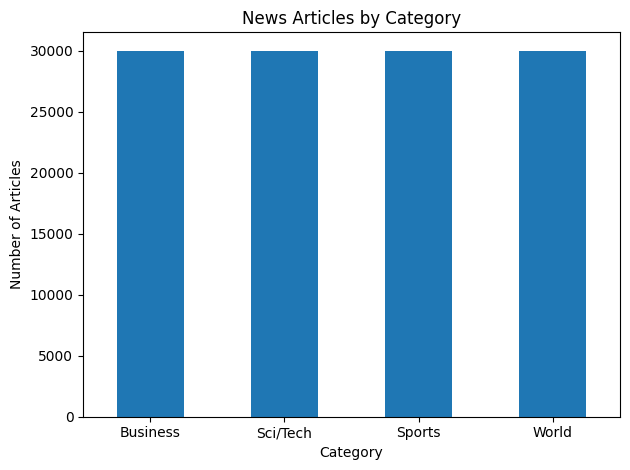

In [6]:
category_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

train_df["category"] = train_df["label"].map(category_names)
test_df["category"] = test_df["label"].map(category_names)

print(train_df["category"].value_counts())

train_df["category"].value_counts().plot(
    kind="bar",
    title="News Articles by Category",
    xlabel="Category",
    ylabel="Number of Articles",
    rot=0
)

plt.tight_layout()
plt.show()

In [7]:
category_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

train_df["category"] = train_df["label"].map(category_names)
test_df["category"] = test_df["label"].map(category_names)

display(train_df[["text", "label", "category"]].head())

,text,label,category
0,Wall St. Bears Claw Back Into the Black (Reute...,2,Business
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,Business
4,"Oil prices soar to all-time record, posing new...",2,Business


In [8]:
print("Missing values:")
print(train_df[["text", "label"]].isnull().sum())

print("\nDuplicate articles:", train_df["text"].duplicated().sum())

print("\nCategory distribution:")
print(train_df["category"].value_counts())

Missing values:
text     0
label    0
dtype: int64

Duplicate articles: 0

Category distribution:
category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


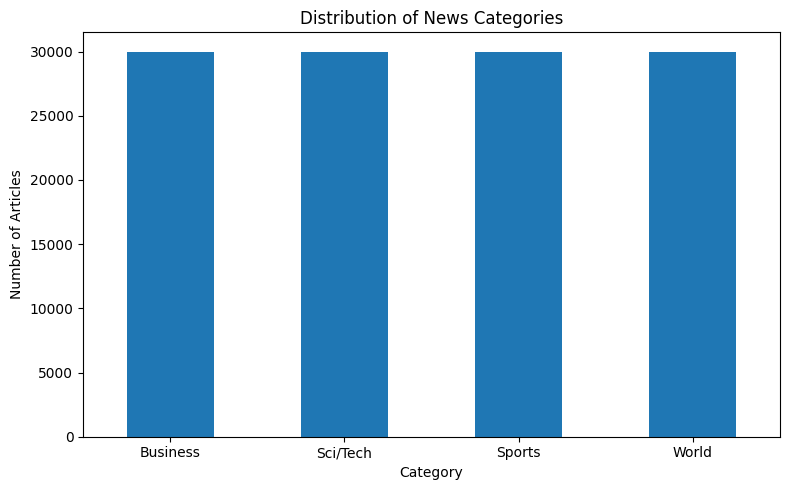

In [9]:
import matplotlib.pyplot as plt

train_df["category"].value_counts().plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Distribution of News Categories")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

In [10]:
X_train = train_df["text"].fillna("").astype(str)
y_train = train_df["label"]

X_test = test_df["text"].fillna("").astype(str)
y_test = test_df["label"]

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))

Training articles: 120000
Testing articles: 7600


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

Training feature matrix: (120000, 50000)
Testing feature matrix: (7600, 50000)


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
print("Training Logistic Regression...")
logistic_model.fit(X_train_tfidf, y_train)

print("Training completed!")

# Make predictions on the test data
y_pred_lr = logistic_model.predict(X_test_tfidf)

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print(f"\nLogistic Regression Accuracy: {accuracy_lr:.4f}")
print(f"Accuracy Percentage: {accuracy_lr * 100:.2f}%")

# Display detailed evaluation
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

Training Logistic Regression...
Training completed!

Logistic Regression Accuracy: 0.9224
Accuracy Percentage: 92.24%

Classification Report:
              precision    recall  f1-score   support

       World       0.93      0.91      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.90      0.89      0.89      1900
    Sci/Tech       0.90      0.91      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



In [13]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the model
svm_model = LinearSVC(random_state=42)

# Train the model
print("Training Linear SVM...")
svm_model.fit(X_train_tfidf, y_train)

print("Training completed!")

# Predict categories for test articles
y_pred_svm = svm_model.predict(X_test_tfidf)

# Calculate accuracy
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print(f"\nLinear SVM Accuracy: {accuracy_svm:.4f}")
print(f"Accuracy Percentage: {accuracy_svm * 100:.2f}%")

# Detailed evaluation
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

Training Linear SVM...
Training completed!

Linear SVM Accuracy: 0.9243
Accuracy Percentage: 92.43%

Classification Report:
              precision    recall  f1-score   support

       World       0.94      0.91      0.92      1900
      Sports       0.96      0.99      0.97      1900
    Business       0.90      0.89      0.90      1900
    Sci/Tech       0.90      0.91      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



Model Comparison:


,Model,Accuracy
0,Logistic Regression,0.922368
1,Linear SVM,0.924342


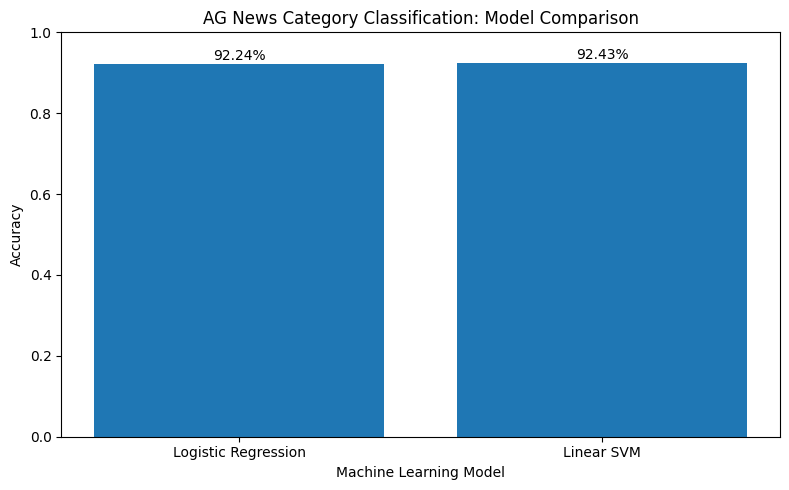

In [14]:

import pandas as pd
import matplotlib.pyplot as plt

# Create a table comparing the two models
results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [accuracy_lr, accuracy_svm]
})

print("Model Comparison:")
display(results_df)

# Plot the comparison
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Model")
plt.title("AG News Category Classification: Model Comparison")

# Display accuracy above each bar
for i, value in enumerate(results_df["Accuracy"]):
    plt.text(i, value + 0.01, f"{value:.2%}", ha="center")

plt.tight_layout()
plt.show()


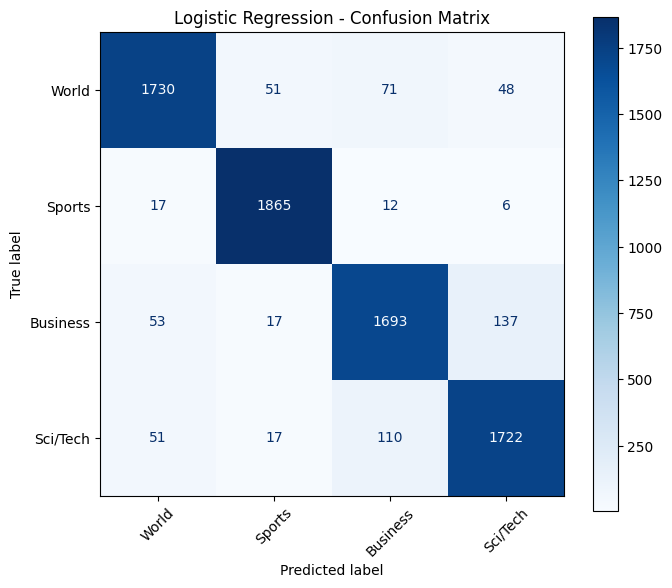

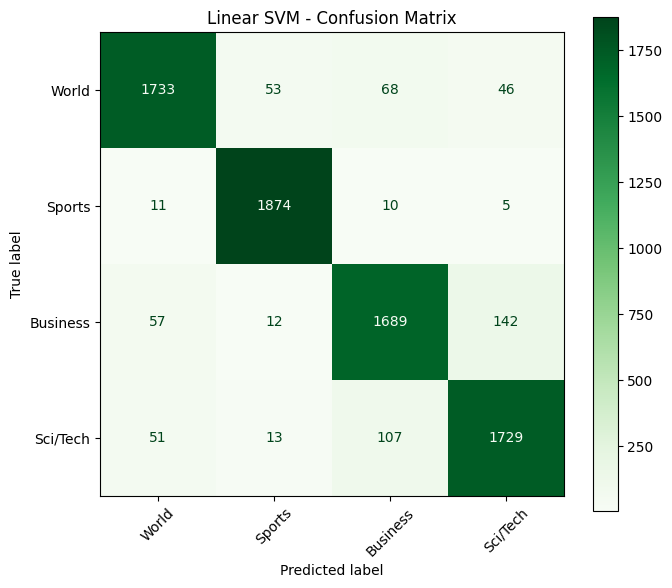

In [15]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

category_labels = ["World", "Sports", "Business", "Sci/Tech"]

# Logistic Regression confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=category_labels,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

# Linear SVM confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    display_labels=category_labels,
    cmap="Greens",
    xticks_rotation=45,
    ax=ax
)
plt.title("Linear SVM - Confusion Matrix")
plt.tight_layout()
plt.show()


In [16]:

# New news examples for testing
news_examples = [
    "The national government announced new policies for international relations.",
    "The football team won the championship after an exciting final.",
    "The stock market rose as major companies reported higher profits.",
    "Scientists developed a new artificial intelligence system for medical research."
]

# Convert the news text using our existing TF-IDF vectorizer
news_examples_tfidf = tfidf.transform(news_examples)

# Predict the category using our trained Linear SVM
predictions = svm_model.predict(news_examples_tfidf)

# Display the predictions
for news, prediction in zip(news_examples, predictions):
    print("News:", news)
    print("Predicted category:", category_names[int(prediction)])
    print("-" * 70)


News: The national government announced new policies for international relations.
Predicted category: World
----------------------------------------------------------------------
News: The football team won the championship after an exciting final.
Predicted category: Sports
----------------------------------------------------------------------
News: The stock market rose as major companies reported higher profits.
Predicted category: Business
----------------------------------------------------------------------
News: Scientists developed a new artificial intelligence system for medical research.
Predicted category: World
----------------------------------------------------------------------


In [17]:

# Save the model comparison table
results_df.to_csv(
    "news_model_comparison_results.csv",
    index=False
)

print("Results saved successfully!")


Results saved successfully!


In [18]:

from google.colab import files

files.download("news_model_comparison_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>